# 08 - Fraud Threshold Optimization

This notebook selects a classification threshold using only a stratified validation split drawn from the original training partition. The untouched final test partition is discarded immediately and is never used for threshold selection. Validation probabilities come from a sigmoid-calibrated copy of the selected hybrid pipeline, fitted only on the inner training subset. The chosen threshold is saved to `models/model_threshold.json` for the Streamlit app.

## 1. Rebuild the training-only validation split

The raw and processed rows are checked for matching cleaned text and labels before reproducing the project's stratified split (`test_size=0.2`, `random_state=42`). A second stratified split reserves validation rows from the training partition. No final-test examples are loaded into the prediction or metric calculations.

In [1]:
import json
import re
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import confusion_matrix, f1_score, precision_score, recall_score
from sklearn.model_selection import train_test_split

PROJECT_DIR = Path.cwd()
if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent
elif PROJECT_DIR.name != "fake-job-detector" and (PROJECT_DIR / "fake-job-detector").is_dir():
    PROJECT_DIR = PROJECT_DIR / "fake-job-detector"

PROCESSED_PATH = PROJECT_DIR / "data" / "processed" / "processed_job_postings.csv"
RAW_PATH = PROJECT_DIR / "data" / "raw" / "DataSet.csv"
BASE_MODEL_PATH = PROJECT_DIR / "models" / "best_hybrid_model.joblib"
THRESHOLD_PATH = PROJECT_DIR / "models" / "model_threshold.json"
for path in (PROCESSED_PATH, RAW_PATH, BASE_MODEL_PATH):
    if not path.is_file():
        raise FileNotFoundError(f"Required threshold-optimization input not found: {path}")

numeric_features = [
    "raw__description_length", "raw__requirements_length", "raw__word_count",
    "raw__character_count", "raw__url_count", "raw__email_count",
    "raw__phone_count", "raw__exclamation_count", "raw__missing_company_profile",
    "raw__contains_urgent_language", "raw__contains_fee_request", "raw__contains_easy_money",
    "raw__contains_no_experience", "raw__contains_work_from_home",
    "raw__contains_cryptocurrency_payment", "raw__contains_whatsapp_or_telegram",
]
categorical_candidates = [
    "location", "department", "salary_range", "employment_type",
    "required_experience", "required_education", "industry", "function",
    "telecommuting", "has_company_logo", "has_questions",
]
text_columns = ["title", "company_profile", "description", "requirements", "benefits"]

processed = pd.read_csv(
    PROCESSED_PATH,
    usecols=["combined_text", "fraudulent", *numeric_features],
    low_memory=False,
)
raw = pd.read_csv(RAW_PATH, low_memory=False).drop_duplicates().copy()
if len(raw) != len(processed):
    raise ValueError(
        f"Raw/processed row counts differ after deduplication: {len(raw)} vs {len(processed)}."
    )
raw_columns = raw.columns.tolist()
categorical_features = [column for column in categorical_candidates if column in raw_columns]
available_text_columns = [column for column in text_columns if column in raw_columns]
if not categorical_features or not available_text_columns:
    raise ValueError("Expected raw categorical metadata and text columns were not found.")
raw = raw[[*categorical_features, "fraudulent", *available_text_columns]].copy()
for column in raw.select_dtypes(include=["object", "string"]).columns:
    raw[column] = raw[column].replace(r"^\s*$", pd.NA, regex=True)

def clean_text(value):
    text = "" if pd.isna(value) else str(value)
    text = text.lower()
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"\b(?:https?://|www\.)\S+", " URL ", text, flags=re.IGNORECASE)
    text = re.sub(r"\b[\w.+%-]+@[\w.-]+\.[a-z]{2,}\b", " EMAIL ", text, flags=re.IGNORECASE)
    return re.sub(r"\s+", " ", text).strip()

raw_text = raw[available_text_columns].fillna("").astype(str).agg(" ".join, axis=1).map(clean_text)
processed_text = processed["combined_text"].fillna("").astype(str)
if not np.array_equal(raw_text.to_numpy(), processed_text.to_numpy()):
    raise ValueError("Raw and processed text do not align row by row; refusing threshold evaluation.")
raw_labels = raw["fraudulent"].astype(str).str.strip().str.lower().to_numpy()
processed_labels = processed["fraudulent"].astype(str).str.strip().str.lower().to_numpy()
if not np.array_equal(raw_labels, processed_labels):
    raise ValueError("Raw and processed labels do not align row by row; refusing threshold evaluation.")
if set(processed_labels) != {"f", "t"}:
    raise ValueError(f"Unexpected fraud labels: {sorted(set(processed_labels))}")

X = processed[["combined_text", *numeric_features]].copy()
for column in categorical_features:
    X[column] = raw[column].reset_index(drop=True)
X = X[["combined_text", *categorical_features, *numeric_features]]
y = pd.Series(processed_labels, index=X.index).map({"f": 0, "t": 1}).astype("int8")

# Reproduce the original outer split, then discard its held-out test partition.
X_train, _unused_final_test, y_train, _unused_final_test_labels = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
X_fit, X_validation, y_fit, y_validation = train_test_split(
    X_train, y_train, test_size=0.2, stratify=y_train, random_state=42
)
del _unused_final_test, _unused_final_test_labels
print(f"Training subset used to fit calibration model: {len(X_fit):,} rows")
print(f"Training-only validation rows used for threshold selection: {len(X_validation):,}")
print("Final test rows used: 0")

Training subset used to fit calibration model: 11,292 rows
Training-only validation rows used for threshold selection: 2,824
Final test rows used: 0


## 2. Get calibrated validation probabilities

The selected pipeline is calibrated using three-fold sigmoid calibration on `X_fit` only. `CalibratedClassifierCV` clones and refits the pipeline within those folds, so the reserved validation labels do not train the estimator or calibrator.

In [2]:
base_pipeline = joblib.load(BASE_MODEL_PATH)
classifier = base_pipeline.named_steps["classifier"]
if classifier.__class__.__name__ == "LinearSVC":
    base_pipeline.set_params(classifier__max_iter=50_000, classifier__tol=1e-2)

calibrated_validation_model = CalibratedClassifierCV(
    estimator=base_pipeline,
    method="sigmoid",
    cv=3,
)
calibrated_validation_model.fit(X_fit, y_fit)
fraud_class_indices = np.flatnonzero(calibrated_validation_model.classes_ == 1)
if len(fraud_class_indices) != 1:
    raise ValueError(f"Could not uniquely identify fraud class 1: {calibrated_validation_model.classes_}")
fraud_probabilities = calibrated_validation_model.predict_proba(X_validation)[:, fraud_class_indices[0]]
if not np.isfinite(fraud_probabilities).all():
    raise ValueError("Calibrated validation probabilities contain non-finite values.")
print(f"Generated {len(fraud_probabilities):,} fraud probabilities from the training-only validation split.")

Generated 2,824 fraud probabilities from the training-only validation split.


## 3. Evaluate thresholds from 0.10 to 0.90

Fraud (label `1`) is the positive class. False-positive rate is `FP / (FP + TN)` and false-negative rate is `FN / (FN + TP)`. Precision, recall, and F1 use fraud as the positive class.

In [3]:
thresholds = np.round(np.arange(0.10, 0.901, 0.05), 2)
if len(thresholds) != 17 or thresholds[0] != 0.10 or thresholds[-1] != 0.90:
    raise RuntimeError(f"Unexpected threshold grid: {thresholds}")

metric_rows = []
for threshold in thresholds:
    predictions = (fraud_probabilities >= threshold).astype("int8")
    tn, fp, fn, tp = confusion_matrix(y_validation, predictions, labels=[0, 1]).ravel()
    metric_rows.append({
        "Threshold": threshold,
        "Fraud precision": precision_score(y_validation, predictions, pos_label=1, zero_division=0),
        "Fraud recall": recall_score(y_validation, predictions, pos_label=1, zero_division=0),
        "Fraud F1-score": f1_score(y_validation, predictions, pos_label=1, zero_division=0),
        "False-positive rate": fp / (fp + tn) if (fp + tn) else 0.0,
        "False-negative rate": fn / (fn + tp) if (fn + tp) else 0.0,
    })

threshold_metrics = pd.DataFrame(metric_rows)
display(threshold_metrics.style.format({column: "{:.3f}" for column in threshold_metrics.columns}))

,Threshold,Fraud precision,Fraud recall,Fraud F1-score,False-positive rate,False-negative rate
0,0.100,0.639,0.942,0.761,0.027,0.058
1,0.150,0.698,0.927,0.796,0.020,0.073
2,0.200,0.748,0.891,0.813,0.015,0.109
3,0.250,0.787,0.861,0.822,0.012,0.139
4,0.300,0.817,0.847,0.832,0.010,0.153
5,0.350,0.830,0.818,0.824,0.009,0.182
6,0.400,0.881,0.810,0.844,0.006,0.190
7,0.450,0.898,0.774,0.831,0.004,0.226
8,0.500,0.909,0.730,0.810,0.004,0.270
9,0.550,0.925,0.723,0.811,0.003,0.277


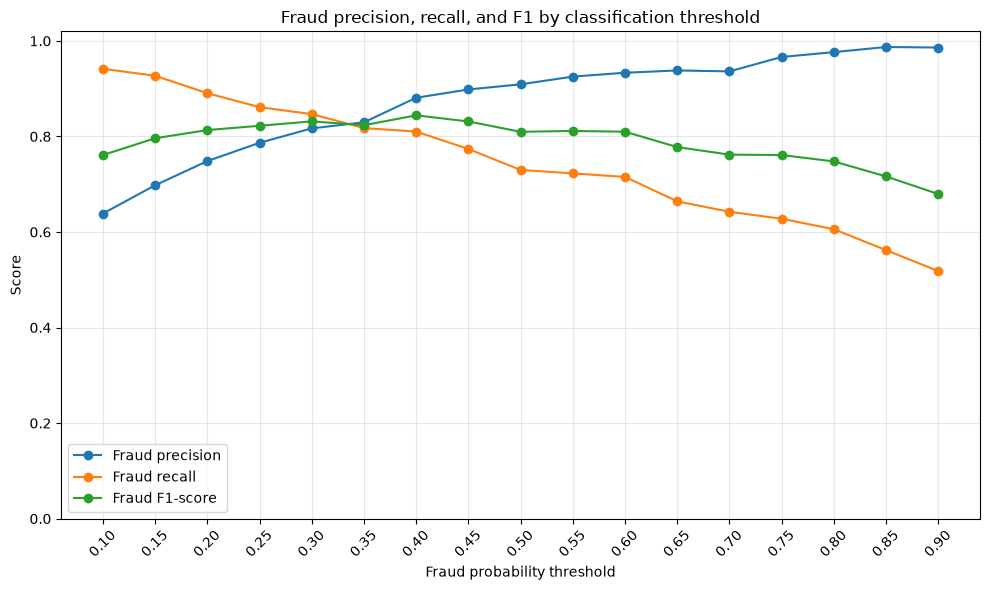

In [4]:
plt.figure(figsize=(10, 6))
for metric in ("Fraud precision", "Fraud recall", "Fraud F1-score"):
    plt.plot(threshold_metrics["Threshold"], threshold_metrics[metric], marker="o", label=metric)
plt.xlabel("Fraud probability threshold")
plt.ylabel("Score")
plt.title("Fraud precision, recall, and F1 by classification threshold")
plt.xticks(thresholds, rotation=45)
plt.ylim(0, 1.02)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## 4. Select and save thresholds

The primary threshold is the one with the highest validation fraud F1-score (ties favor the higher threshold). For a safety-focused alternative, the notebook uses a stated target of at least 90% fraud recall and chooses the highest threshold that reaches it. If no tested threshold reaches that target, it reports and saves the tested threshold with the highest observed recall instead.

In [5]:
best_row = threshold_metrics.sort_values(
    ["Fraud F1-score", "Threshold"], ascending=[False, False]
).iloc[0]
recall_target = 0.90
high_recall_candidates = threshold_metrics[threshold_metrics["Fraud recall"] >= recall_target]
if not high_recall_candidates.empty:
    high_recall_row = high_recall_candidates.sort_values("Threshold", ascending=False).iloc[0]
    recall_target_met = True
else:
    high_recall_row = threshold_metrics.sort_values(
        ["Fraud recall", "Threshold"], ascending=[False, True]
    ).iloc[0]
    recall_target_met = False

threshold_config = {
    "selected_threshold": float(best_row["Threshold"]),
    "selection_metric": "fraud_f1_score",
    "validation_fraud_f1_score": float(best_row["Fraud F1-score"]),
    "high_recall_threshold": float(high_recall_row["Threshold"]),
    "high_recall": float(high_recall_row["Fraud recall"]),
    "high_recall_target": recall_target,
    "high_recall_target_met": recall_target_met,
    "validation_rows": int(len(y_validation)),
    "final_test_rows_used": 0,
    "probability_model": "sigmoid-calibrated selected hybrid pipeline",
}
THRESHOLD_PATH.write_text(json.dumps(threshold_config, indent=2) + "\n", encoding="utf-8")

print(f"Best fraud F1 threshold: {best_row['Threshold']:.2f}")
print(f"  Precision={best_row['Fraud precision']:.3f}, recall={best_row['Fraud recall']:.3f}, F1={best_row['Fraud F1-score']:.3f}")
print(f"High-recall threshold: {high_recall_row['Threshold']:.2f} (recall={high_recall_row['Fraud recall']:.3f}; 90% target met={recall_target_met})")
print(f"Saved threshold configuration to {THRESHOLD_PATH}")

Best fraud F1 threshold: 0.40
  Precision=0.881, recall=0.810, F1=0.844
High-recall threshold: 0.15 (recall=0.927; 90% target met=True)
Saved threshold configuration to <PROJECT_ROOT>\models\model_threshold.json


## Precision-recall trade-off

Lowering the threshold usually flags more postings as potential fraud. This tends to increase recall (fewer fraudulent postings are missed), but can decrease precision and increase the false-positive rate, meaning more legitimate postings are flagged. Raising the threshold usually improves precision and reduces false alarms, but lowers recall and can increase missed fraud. The F1-selected threshold balances precision and recall on this validation split; the high-recall alternative deliberately favors catching fraud and may create more false alarms. Choose the operating point according to the consequences of each type of error, and do not treat a model score as proof that a posting is fraudulent.